In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt 



In [2]:

df = pd.read_csv("student_pass_dataset.csv")
X = df.drop(columns="passed")
y = df["passed"]


In [3]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

def predict(X,w,b):
    z = np.dot(X,w)+b
    return 1/(1+np.exp(-z))

def compute_cost(X,y,w,b,lambda_):
    m = X.shape[0]
    predicted = predict(X,w,b)
    one_ = np.ones(m)
    error = ((y*np.log(predicted))+ ((one_-y)* np.log(one_-predicted)))
    penalty = (lambda_ / (2*m))*(w ** 2)
    return ((-1/m) * np.sum(error)) + np.sum(penalty)

def compute_gradient(X,y,w,b,lambda_):
    m,n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0
    error = predict(X,w,b) - y
    penalty = (lambda_/ m)* w
    dj_dw = ((1/m)* (X.T @ error)) + penalty
    dj_db = np.sum(error) / m
    return dj_dw,dj_db










In [4]:
def gradient_descent(X,y,w,b,learning_rate,iterations,lambda_):
        cost_history = []
        iters = range(iterations)
        for i in range(iterations): 
            dj_dw,dj_db = compute_gradient(X,y,w,b,lambda_)
            w = w - (learning_rate * dj_dw)
            b = b - (learning_rate * dj_db)
            cost_history.append(compute_cost(X,y,w,b,lambda_))
            


        return w,b,cost_history,iters
            
        

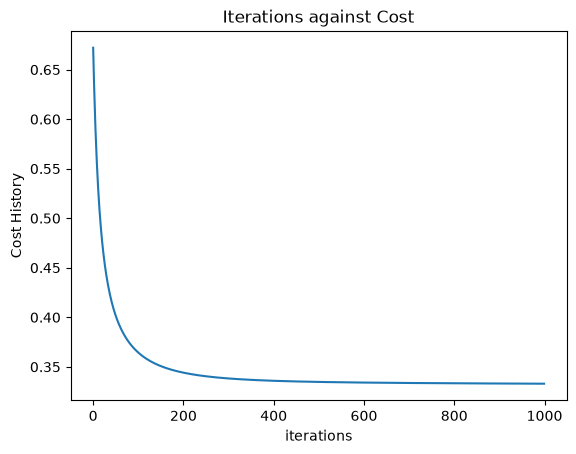

0.98


In [5]:
m,n = X_train_scaled.shape
w = np.zeros(n)
b=0
model= LogisticRegression(max_iter=1000)
model.fit(X_train_scaled,y_train)
w1= model.coef_
b1 = model.intercept_
w,b,cost_history,iters = gradient_descent(X_train_scaled,y_train,w,b,0.1,1000,1)

plt.plot(iters,cost_history)


plt.xlabel("iterations")
plt.ylabel("Cost History")
plt.title("Iterations against Cost")

plt.show()
# print(w1)
# print(w)
# print(cost_history[0])

probabilities = predict(X_test_scaled,w,b)
predictions = (probabilities >= 0.5).astype(int)
correct = predictions == y_test



predictions1 = model.predict(X_test_scaled)
correct1 = predictions1 == y_test
accuracy = predictions1 == predictions
# print(correct.mean())
# print(correct1.mean())
# print(y_test.mean())

print(accuracy.mean())
